# Exploratory data analysis (EDA) of the FActScore dev set

This notebook looks at the **raw data** before any modelling. It answers: what is in the files, how the labels are
balanced, what facts and passages look like, and which properties of the data should shape our preprocessing.

It complements `m1_analysis.ipynb`. That notebook only reads saved experiment results; this one reads the raw
`.jsonl` files with **pandas**. Every number is computed here from the data, and nothing is typed in by hand.

**Run:** Kernel → Restart & Run All, with the kernel "Python 3.10 (cm3604)". If the data is not in `<repo>/data`,
set the environment variable `CM3604_DATA_DIR` first. Figures are saved to `report/figures/m1_eda_*.png`.

| Section | Question |
|---|---|
| 1 | What do the raw files look like? |
| 2 | Does our flattened table match what `factchecking_main.py` reads? |
| 3 | How are the labels distributed? |
| 4 | Does the label mix depend on the person (rarity, region)? |
| 5 | What do the facts look like (length, pronouns, numbers)? |
| 6 | What do the passages look like (count, length, tags, duplication)? |
| 7 | What does preprocessing remove from a fact? |
| 8 | How much of a fact appears in its passages, before and after preprocessing? |
| 9 | Data-quality checks |
| 10 | Summary: findings → preprocessing decisions |

In [1]:
# ---------------------------------------------------------------------------------------------------------------
# Setup: find the repository, the data and the figure folder; plotting style.
# ---------------------------------------------------------------------------------------------------------------
import json
import os
import re
import sys

def auc(scores, gold):
    # Mann-Whitney AUC: P(score of a random S fact > score of a random NS fact), ties count 1/2.
    s, y = np.asarray(scores, dtype=float), np.asarray(gold) == "S"
    diff = s[y][:, None] - s[~y][None, :]
    return ((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_repo_root(start):
    # Walk up from the current folder until we find factcheck.py, so this works wherever Jupyter was started.
    path = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(path, "factcheck.py")):
            return path
        parent = os.path.dirname(path)
        if parent == path:
            raise FileNotFoundError("factcheck.py not found above " + start + "; set CM3604_REPO")
        path = parent

REPO_ROOT = os.environ.get("CM3604_REPO") or find_repo_root(os.getcwd())
DATA_DIR = os.environ.get("CM3604_DATA_DIR", os.path.join(REPO_ROOT, "data"))
FIG_DIR = os.path.join(REPO_ROOT, "report", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
sys.path.insert(0, REPO_ROOT)
LABELS_PATH = os.path.join(DATA_DIR, "dev_labeled_ChatGPT.jsonl")
PASSAGES_PATH = os.path.join(DATA_DIR, "passages_bm25_ChatGPT_humfacts.jsonl")
for p in (LABELS_PATH, PASSAGES_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(p + " not found. Put the data in <repo>/data or set CM3604_DATA_DIR.")

# Same colour meaning as in m1_analysis.ipynb: S = blue, NS = orange, IR = aqua.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
LABEL_COLORS = {"S": BLUE, "NS": ORANGE, "IR": AQUA}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 90)

def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print("saved", os.path.relpath(path, REPO_ROOT))

print("Repository:", REPO_ROOT)
print("Data:      ", DATA_DIR)

Repository: D:\IIT\Third year\DL\DL_CW\cm3604-cw
Data:       D:\IIT\Third year\DL\DL_CW\cm3604-cw\data


## 1. The raw files

There are two files, both in **JSON Lines** format (one JSON object per line):

1. **`dev_labeled_ChatGPT.jsonl`**: one line per **person** (topic). Each line holds ChatGPT's generated
   biography (`output`), the person's rarity and region (`cat`), and `annotations`: the biography split into
   sentences, each with human-written **atomic facts** and a label (S / NS / IR).
2. **`passages_bm25_ChatGPT_humfacts.jsonl`**: one line per **fact** (`sent`), with the Wikipedia `passages`
   that the BM25 search engine retrieved for it from the person's page (`name`).

`pd.read_json(..., lines=True)` reads a JSON Lines file straight into a DataFrame.

In [2]:
topics = pd.read_json(LABELS_PATH, lines=True)
print(topics.shape, "-> one row per person")
topics["rarity"] = topics["cat"].str[0]      # cat = [rarity, region]
topics["region"] = topics["cat"].str[1]
topics["n_sentences"] = topics["annotations"].apply(lambda a: len(a) if a else 0)
topics[["topic", "rarity", "region", "n_sentences", "output"]].head()

(31, 5) -> one row per person


,topic,rarity,region,n_sentences,output
0,Marianne McAndrew,very rare,North America,1,"Marianne McAndrew is an American actress and singer, born on November 21, 1942, in Cle..."
1,Gerhard Fischer (inventor),very rare,North America,2,Gerhard Fischer is an inventor and entrepreneur who is best known for inventing the fi...
2,Joey D. Vieira,very rare,North America,1,"Joey D. Vieira is an American actor and stunt performer who was born on July 23, 1937,..."
3,Taral Hicks,very rare,North America,1,"Taral Hicks is an American actress and singer, born on September 21, 1974, in The Bron..."
4,Vincenzo Tusa,very rare,Europe/Middle East,2,"Vincenzo Tusa is an Italian politician who was born on February 1, 1972, in Palermo, I..."


In [3]:
# One annotation (= one sentence of the biography), to see the nested structure.
first = topics.loc[0, "annotations"][0]
print(json.dumps({k: first[k] for k in ["text", "is-relevant", "human-atomic-facts"]}, indent=2)[:900])

{
  "text": "Marianne McAndrew is an American actress and singer, born on November 21, 1942, in Cleveland, Ohio.",
  "is-relevant": true,
  "human-atomic-facts": [
    {
      "text": "Marianne McAndrew is an American.",
      "label": "NS"
    },
    {
      "text": "Marianne McAndrew is an actress.",
      "label": "S"
    },
    {
      "text": "Marianne McAndrew is a singer.",
      "label": "NS"
    },
    {
      "text": "Marianne McAndrew was born on November 21, 1942.",
      "label": "NS"
    },
    {
      "text": "Marianne McAndrew was born in Cleveland.",
      "label": "NS"
    },
    {
      "text": "Cleveland is in Ohio.",
      "label": "IR"
    }
  ]
}


**Flattening.** The labels sit three levels deep (person → sentence → fact). We turn this into one tidy table with
**one row per fact**, which makes every later question a simple pandas operation. `gold` is the label used for
evaluation: `factchecking_main.py` maps IR to NS.

In [4]:
rows = []
for t in topics.itertuples():
    for sent_id, sent in enumerate(t.annotations or []):
        for f in sent["human-atomic-facts"] or []:
            rows.append({"topic": t.topic, "rarity": t.rarity, "region": t.region, "sentence_id": sent_id,
                         "is_relevant": sent["is-relevant"], "sentence": sent["text"],
                         "fact": f["text"], "label": f["label"]})
facts = pd.DataFrame(rows)
facts["gold"] = np.where(facts["label"] == "S", "S", "NS")       # IR -> NS, exactly as factchecking_main.py
print(facts.shape, "-> one row per fact")
facts.head(8)[["topic", "sentence_id", "fact", "label", "gold"]]

(221, 9) -> one row per fact


,topic,sentence_id,fact,label,gold
0,Marianne McAndrew,0,Marianne McAndrew is an American.,NS,NS
1,Marianne McAndrew,0,Marianne McAndrew is an actress.,S,S
2,Marianne McAndrew,0,Marianne McAndrew is a singer.,NS,NS
3,Marianne McAndrew,0,"Marianne McAndrew was born on November 21, 1942.",NS,NS
4,Marianne McAndrew,0,Marianne McAndrew was born in Cleveland.,NS,NS
5,Marianne McAndrew,0,Cleveland is in Ohio.,IR,NS
6,Gerhard Fischer (inventor),0,Gerhard Fischer is an inventor.,S,S
7,Gerhard Fischer (inventor),0,Gerhard Fischer is an entrepreneur.,S,S


In [5]:
# The passages file covers facts from far more people than this dev set, so keep only the facts we use.
# factchecking_main.py stores passages in a dict keyed by the fact text, so for a repeated fact the LAST line wins;
# drop_duplicates(keep="last") reproduces exactly that.
passages_raw = pd.read_json(PASSAGES_PATH, lines=True)
print("passages file:", passages_raw.shape[0], "lines,", passages_raw["sent"].nunique(), "distinct facts")
used = passages_raw[passages_raw["sent"].isin(facts["fact"])].drop_duplicates("sent", keep="last")

# explode(): one row per (fact, passage) pair; then unpack the {"title", "text"} dicts into columns.
pairs = used.explode("passages").reset_index(drop=True)
pairs = pd.concat([pairs[["name", "sent"]], pd.json_normalize(pairs["passages"])], axis=1)
pairs = pairs.rename(columns={"sent": "fact"})
print(pairs.shape, "-> one row per (fact, passage) pair")
pairs.head(3)

passages file: 5427 lines, 5373 distinct facts


(689, 4) -> one row per (fact, passage) pair


,name,fact,title,text
0,Marianne McAndrew,Marianne McAndrew is an American.,Marianne McAndrew,<s>Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as I...
1,Marianne McAndrew,Marianne McAndrew is an American.,Marianne McAndrew,"Doris Williams in ""Growing Up Brady"", a TV film about the popular show. McAndrew, alo..."
2,Marianne McAndrew,Marianne McAndrew is an actress.,Marianne McAndrew,<s>Marianne McAndrew Marianne Christine McAndrew is an actress known for her role as I...


## 2. Consistency check with `factchecking_main.py`

Before analysing anything, we make sure our table describes **exactly** the data the graded program reads. We
load the data with the program's own (unmodified) reader functions and compare.

In [6]:
import contextlib, io
import factchecking_main as fm
with contextlib.redirect_stdout(io.StringIO()):
    examples = fm.read_fact_examples(LABELS_PATH, fm.read_passages(PASSAGES_PATH))

assert len(examples) == len(facts), (len(examples), len(facts))
assert [e.fact for e in examples] == facts["fact"].tolist()
assert [e.label for e in examples] == facts["label"].tolist()
assert sum(len(e.passages) for e in examples) == facts["fact"].map(pairs.groupby("fact").size()).sum()
print(f"OK: {len(examples)} facts, same order, same labels, same passages as factchecking_main.py")

C:\Users\LENOVO\.conda\envs\cm3604\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK: 221 facts, same order, same labels, same passages as factchecking_main.py


## 3. Label distribution

The **majority-class baseline** is the accuracy of always predicting the most common gold label. Any useful model
must beat it, and the 75% target for Part 1 is well above it.

,facts,share
label,,
S,112,0.507
NS,93,0.421
IR,16,0.072


Binary gold labels (IR -> NS): {'S': 112, 'NS': 109}
Majority-class baseline accuracy: 0.507


saved report\figures\m1_eda_labels.png


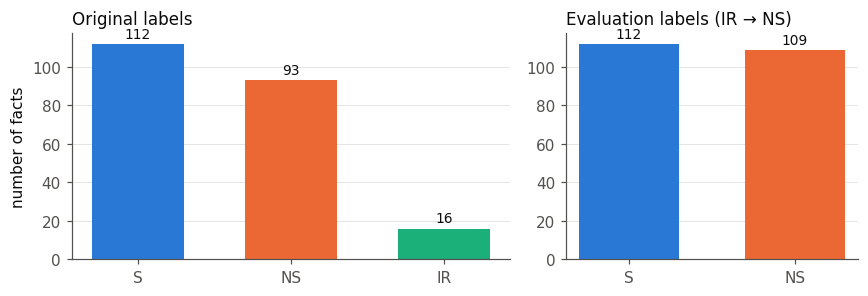

In [7]:
label_counts = facts["label"].value_counts().reindex(["S", "NS", "IR"])
gold_counts = facts["gold"].value_counts().reindex(["S", "NS"])
summary = pd.DataFrame({"facts": label_counts, "share": (label_counts / len(facts)).round(3)})
display(summary)
print("Binary gold labels (IR -> NS):", gold_counts.to_dict())
print(f"Majority-class baseline accuracy: {gold_counts.max() / len(facts):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), gridspec_kw={"width_ratios": [3, 2]})
for ax, counts, title in [(axes[0], label_counts, "Original labels"), (axes[1], gold_counts, "Evaluation labels (IR → NS)")]:
    bars = ax.bar(counts.index, counts.values, color=[LABEL_COLORS[l] for l in counts.index], width=0.6)
    ax.bar_label(bars, padding=2, fontsize=9, color=INK)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of facts")
fig.tight_layout()
save(fig, "m1_eda_labels.png")
plt.show()

**Reading it.** The two evaluation classes are almost balanced, so accuracy is a fair metric here. A model that
says "S" for everything scores only about 51%. IR ("irrelevant") facts are a small group, and they are scored as
NS.

## 4. Does the label mix depend on the person?

FActScore tags each person with how often they appear on the web (**rarity**: very rare → very frequent) and a
**region**. ChatGPT tends to know less about rare people, so we might expect more unsupported facts for them.
**Caution:** with only 31 people (and some groups of 1–4 people), these are descriptive patterns, not proven
effects.

In [8]:
print(f"{facts['topic'].nunique()} people, {len(facts)} facts; facts per person:")
display(facts.groupby("topic").size().describe().round(1).to_frame("facts per person").T)

rarity_order = ["very rare", "rare", "medium", "freq", "very freq"]
by_rarity = (facts.groupby("rarity")
             .agg(people=("topic", "nunique"), facts=("fact", "size"), share_S=("gold", lambda g: (g == "S").mean()))
             .reindex([r for r in rarity_order if r in set(facts["rarity"])]))
display(by_rarity.style.format({"share_S": "{:.2f}"}))

by_region = (facts.groupby("region")
             .agg(people=("topic", "nunique"), facts=("fact", "size"), share_S=("gold", lambda g: (g == "S").mean()))
             .sort_values("share_S"))
display(by_region.style.format({"share_S": "{:.2f}"}))

31 people, 221 facts; facts per person:


,count,mean,std,min,25%,50%,75%,max
facts per person,31.0,7.1,2.5,5.0,5.5,7.0,8.0,18.0


,people,facts,share_S
rarity,,,
very rare,9,60,0.43
rare,8,56,0.45
medium,10,68,0.50
freq,1,8,0.50
very freq,3,29,0.79


,people,facts,share_S
region,,,
Asia/Pacific,7,55,0.44
Latin America/Africa,10,66,0.52
Europe/Middle East,4,26,0.54
North America,10,74,0.54


saved report\figures\m1_eda_rarity.png


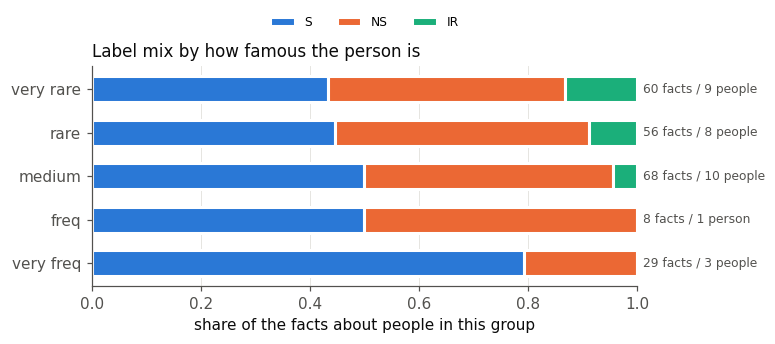

In [9]:
# 100% stacked bars: the share of S / NS / IR facts within each rarity group.
share = pd.crosstab(facts["rarity"], facts["label"], normalize="index").reindex(by_rarity.index)[["S", "NS", "IR"]]
fig, ax = plt.subplots(figsize=(6.4, 2.6))
left = np.zeros(len(share))
for label in ["S", "NS", "IR"]:
    ax.barh(share.index, share[label], left=left, color=LABEL_COLORS[label], label=label, height=0.6,
            edgecolor="white", linewidth=2)           # white gap between segments
    left += share[label].to_numpy()
for y, (r, row) in enumerate(by_rarity.iterrows()):
    n_people = int(row["people"])
    ax.text(1.01, y, f"{int(row['facts'])} facts / {n_people} {'person' if n_people == 1 else 'people'}",
            va="center", fontsize=8, color=INK_2)
ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_xlabel("share of the facts about people in this group")
ax.set_title("Label mix by how famous the person is", loc="left")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.12), fontsize=8)
ax.grid(axis="y", visible=False)
save(fig, "m1_eda_rarity.png")
plt.show()

**Reading it.** The share of supported facts rises with how famous the person is: it is lowest for "very rare"
people and clearly highest for the "very freq" group. That fits the expectation that ChatGPT invents more about
people it has seen less often. But the extreme groups are tiny (the "freq" group is a single person), so treat
this as a description of this dev set, not a finding.

## 5. What do the facts look like?

We measure each fact's length in words (a plain whitespace split), whether it starts with a **pronoun** ("He",
"She", "They", …; the person is then not named in the fact), and whether it contains a **number** (years, dates,
counts). These are the kinds of facts that word overlap could find hard or easy.

In [10]:
PRONOUN_RE = re.compile(r"^(He|She|They|His|Her|Hers|It|Its|Their|Theirs|Him|Them)\b")
facts["n_words"] = facts["fact"].str.split().str.len()
facts["starts_with_pronoun"] = facts["fact"].str.match(PRONOUN_RE)
facts["has_number"] = facts["fact"].str.contains(r"\d")

display(facts.groupby("label")["n_words"].describe().reindex(["S", "NS", "IR"]).round(2))
display(pd.crosstab(facts["label"], [facts["starts_with_pronoun"].rename("pronoun start"),
                                     facts["has_number"].rename("has number")], margins=True)
        .reindex(["S", "NS", "IR", "All"]))
print("Share of facts starting with a pronoun:", round(facts["starts_with_pronoun"].mean(), 3))
# How well would length alone separate the classes? Use "shorter = more likely S" as a score and compute its AUC
# (defined in section 8; 0.5 = useless, 1.0 = perfect).
print(f"AUC of 'shorter fact = supported' as a score: {auc(-facts['n_words'], facts['gold']):.3f}")
print("Share of IR facts containing a number:", round(facts.loc[facts.label == "IR", "has_number"].mean(), 3))

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
S,112.0,6.26,1.96,4.0,5.0,6.0,7.25,12.0
NS,93.0,7.23,2.19,4.0,5.0,7.0,9.00,14.0
IR,16.0,7.62,2.06,4.0,6.0,8.0,9.00,10.0


pronoun start False       True       All
has number    False True False True     
label                                   
S                74    9    24    5  112
NS               46   12    30    5   93
IR                7    7     1    1   16
All             127   28    55   11  221

Share of facts starting with a pronoun: 0.299
AUC of 'shorter fact = supported' as a score: 0.643
Share of IR facts containing a number: 0.5


saved report\figures\m1_eda_fact_length.png


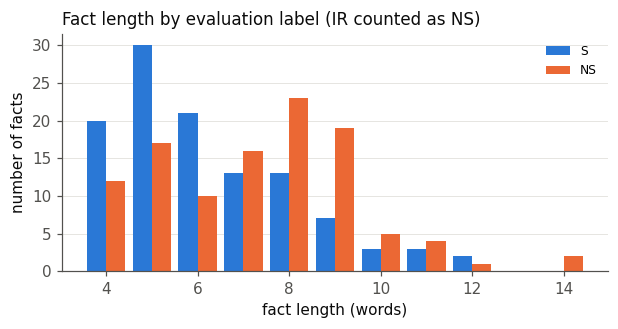

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
bins = np.arange(facts["n_words"].min(), facts["n_words"].max() + 2) - 0.5   # one bin per word count
width = 0.42
for offset, g in [(-width / 2, "S"), (width / 2, "NS")]:
    counts, edges = np.histogram(facts.loc[facts["gold"] == g, "n_words"], bins=bins)
    ax.bar((edges[:-1] + edges[1:]) / 2 + offset, counts, width=width, color=LABEL_COLORS[g], label=g)
ax.set_xlabel("fact length (words)")
ax.set_ylabel("number of facts")
ax.set_title("Fact length by evaluation label (IR counted as NS)", loc="left")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
save(fig, "m1_eda_fact_length.png")
plt.show()

**Reading it.** Facts are short, typically a single clause of a handful of words. NS facts are on average about
one word longer than S facts (more detail gives more room to be wrong), but the two distributions overlap
heavily. The length-only AUC printed above shows that length is a weak signal on its own, so the content has to
be compared with the evidence. Many
facts start with a pronoun, so the person's name is often not in the fact at all. Facts with numbers matter
because a wrong year or date is a common way for a fact to be unsupported.

## 6. What do the passages look like?

Each fact comes with a few passages retrieved from the person's Wikipedia page. We look at how many there are, how
long they are, whether they contain the `<s>…</s>` sentence markers, and how often the **same** passage is shared
between facts, which matters for efficiency.

In [12]:
from factcheck import split_sentences, tokenize

pairs["n_chars"] = pairs["text"].str.len()
pairs["n_tokens"] = pairs["text"].apply(lambda t: len(tokenize(t)))
pairs["has_s_tags"] = pairs["text"].str.contains("<s>", regex=False)
pairs["n_sentences"] = pairs["text"].apply(lambda t: len(split_sentences(t)))
pairs["title_is_person"] = pairs["title"] == pairs["name"]

per_fact = pairs.groupby("fact").size()
print("Passages per fact:", per_fact.value_counts().sort_index().to_dict())
display(pairs[["n_chars", "n_tokens", "n_sentences"]].describe().round(1).T)
print(f"(fact, passage) pairs: {len(pairs)} distinct; factchecking_main.py sees {int(facts['fact'].map(per_fact).sum())} "
      "because one fact text appears twice (see section 9)")
print(f"Passages containing <s> tags: {pairs['has_s_tags'].sum()} of {len(pairs)} ({pairs['has_s_tags'].mean():.1%})")
print(f"Passage title == the person:  {pairs['title_is_person'].mean():.0%}")
n_unique = pairs["text"].nunique()
print(f"Distinct passage texts: {n_unique} for {len(pairs)} (fact, passage) pairs "
      f"-> each passage is reused {len(pairs) / n_unique:.1f} times on average")
fact_len = facts["fact"].apply(lambda t: len(tokenize(t))).median()
print(f"Median length ratio passage/fact (tokens): {pairs['n_tokens'].median() / fact_len:.0f}x")

Passages per fact: {2: 66, 3: 97, 4: 19, 5: 38}


,count,mean,std,min,25%,50%,75%,max
n_chars,689.0,875.6,353.5,23.0,672.0,1021.0,1138.0,1295.0
n_tokens,689.0,143.4,60.7,2.0,102.0,169.0,188.0,213.0
n_sentences,689.0,8.7,4.0,1.0,6.0,9.0,11.0,18.0


(fact, passage) pairs: 689 distinct; factchecking_main.py sees 692 because one fact text appears twice (see section 9)
Passages containing <s> tags: 549 of 689 (79.7%)
Passage title == the person:  100%
Distinct passage texts: 102 for 689 (fact, passage) pairs -> each passage is reused 6.8 times on average
Median length ratio passage/fact (tokens): 24x


saved report\figures\m1_eda_passage_length.png


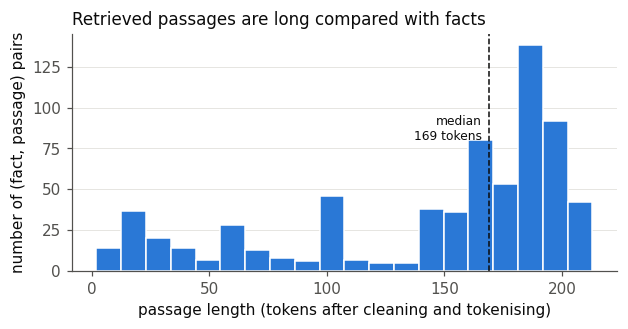

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(pairs["n_tokens"], bins=20, color=BLUE, edgecolor="white", linewidth=1)
med = pairs["n_tokens"].median()
ax.axvline(med, color=INK, linestyle="--", linewidth=1)
ax.text(med - 3, ax.get_ylim()[1] * 0.6, f"median\n{med:.0f} tokens", ha="right", va="center", fontsize=8, color=INK)
ax.set_xlabel("passage length (tokens after cleaning and tokenising)")
ax.set_ylabel("number of (fact, passage) pairs")
ax.set_title("Retrieved passages are long compared with facts", loc="left")
ax.grid(axis="x", visible=False)
save(fig, "m1_eda_passage_length.png")
plt.show()

**Reading it.** Passages are many times longer than facts. That is why a similarity score that divides by the
*passage* length (precision, Jaccard) is dominated by passage length, while recall, which divides by the *fact*
length, is not. Most passages carry `<s>` markers, which a tokenizer must strip (otherwise a fake word "s"
appears) and which a sentence splitter can use. Every passage comes from the person's own page, so the person's
name appears in almost all of them. Finally, passages are heavily reused across facts about the same person, so
caching preprocessed passages saves most of the work.

## 7. What does preprocessing remove from a fact?

We compare the raw tokens of each fact (lowercase, regex split) with the tokens left after the chosen pipeline:
stop words removed, Porter stemming, then the person's name removed. This shows how few **content words** a
fact really has.

In [14]:
from factcheck import TextPreprocessor, STOPWORDS
pre = TextPreprocessor()   # the chosen configuration: stop words removed, Porter stemming, min length 2
passages_by_fact = {e.fact: e.passages for e in examples}

def name_tokens(fact):
    return set().union(*[pre.process_set(p["title"]) for p in passages_by_fact[fact]])

facts["raw_tokens"] = facts["fact"].apply(tokenize)
facts["n_raw"] = facts["raw_tokens"].str.len()
facts["n_stopwords"] = facts["raw_tokens"].apply(lambda ts: sum(t in STOPWORDS for t in ts))
facts["content"] = facts["fact"].apply(lambda f: [w for w in pre.process(f) if w not in name_tokens(f)])
facts["n_content"] = facts["content"].str.len()
facts["n_name"] = facts["fact"].apply(lambda f: sum(w in name_tokens(f) for w in pre.process(f)))

cols = ["n_raw", "n_stopwords", "n_name", "n_content"]
display(facts.groupby("gold")[cols].mean().round(2).reindex(["S", "NS"]))
print(f"On average {facts['n_stopwords'].sum() / facts['n_raw'].sum():.0%} of a fact's tokens are stop words and "
      f"{facts['n_name'].sum() / facts['n_raw'].sum():.0%} are the person's name.")
print("Facts by number of content words left:", facts["n_content"].value_counts().sort_index().to_dict())
facts[["fact", "gold", "content"]].sample(6, random_state=0)

,n_raw,n_stopwords,n_name,n_content
gold,,,,
S,6.29,2.50,0.97,2.81
NS,7.34,2.86,0.87,3.59


On average 39% of a fact's tokens are stop words and 14% are the person's name.
Facts by number of content words left: {0: 4, 1: 29, 2: 55, 3: 39, 4: 49, 5: 26, 6: 12, 7: 5, 8: 1, 9: 1}


,fact,gold,content
129,He has worked at Continuum Analytics.,S,"[work, continuum, analyt]"
202,She has supported The National Foundation for Autism Research.,NS,"[support, nation, foundat, autism, research]"
138,Jessica Barboza is a fashion model.,S,"[fashion, model]"
66,Trivisonno worked at WTAM.,S,"[work, wtam]"
180,He quickly developed a passion for the sport.,NS,"[quickli, develop, passion, sport]"
145,"With CSKA, he won international titles.",S,"[cska, won, intern, titl]"


## 8. How much of a fact appears in its passages?

For each fact we compute **recall**: the share of the fact's words that also appear in a passage, taking the best
passage. We do it twice: on raw tokens (lowercase only), and with the chosen preprocessing (`checker.score()`
from `factcheck.py`). A good representation should give S facts high recall and NS facts low recall. **AUC** (the
probability that a random S fact scores higher than a random NS fact) summarises the separation in one number.

In [15]:
from factcheck import WordRecallThresholdFactChecker

def raw_recall(fact, passages):
    f = set(tokenize(fact))
    return max((len(f & set(tokenize(p["text"]))) / len(f) for p in passages), default=0.0) if f else 0.0

checker = WordRecallThresholdFactChecker()
facts["recall_raw"] = [raw_recall(e.fact, e.passages) for e in examples]
facts["recall_chosen"] = [checker.score(e.fact, e.passages) for e in examples]

table = facts.groupby("gold")[["recall_raw", "recall_chosen"]].agg(["mean", "median"]).reindex(["S", "NS"]).round(3)
display(table)
for col in ["recall_raw", "recall_chosen"]:
    print(f"{col:14s} AUC = {auc(facts[col], facts['gold']):.4f}")
print(f"Facts with every raw token found in some passage: S {facts.loc[facts.gold == 'S', 'recall_raw'].eq(1).mean():.0%}, "
      f"NS {facts.loc[facts.gold == 'NS', 'recall_raw'].eq(1).mean():.0%}")

recall_raw        recall_chosen       
           mean median          mean median
gold                                       
S         0.825  0.833         0.789   1.00
NS        0.588  0.600         0.267   0.25

recall_raw     AUC = 0.8223
recall_chosen  AUC = 0.8975
Facts with every raw token found in some passage: S 40%, NS 3%


**Reading it.** On raw tokens, NS facts still get a fairly high recall, because stop words and the person's name
match in almost every passage. After preprocessing, NS recall drops much further than S recall, so the gap
between the classes widens and the AUC rises (see the table and the two AUC lines). The chosen-pipeline AUC printed here must equal the 0.8975 reported by `run_grid.py`, since it is the
same computation.

## 9. Data-quality checks

In [16]:
checks = {
    "facts with no passages": int((per_fact.reindex(facts["fact"]).fillna(0) == 0).sum()),
    "empty passage texts": int((pairs["text"].str.strip() == "").sum()),
    "duplicate fact texts (same sentence labelled twice)": int(facts["fact"].duplicated().sum()),
    "facts in irrelevant sentences": int((~facts["is_relevant"]).sum()),
    "passages containing non-ASCII characters": int(pairs["text"].str.contains(r"[^\x00-\x7F]").sum()),
    "facts containing non-ASCII characters": int(facts["fact"].str.contains(r"[^\x00-\x7F]").sum()),
}
display(pd.Series(checks, name="count").to_frame())
non_ascii_share = pairs["text"].str.contains(r"[^\x00-\x7F]").mean()   # used in the summary table

dups = facts[facts["fact"].duplicated(keep=False)][["topic", "sentence_id", "fact", "label"]]
print("Duplicated facts:"); display(dups)
# factchecking_main.py keys passages by fact text, so every copy of a duplicated fact gets the SAME passages
# (the last line in the passages file). Which person's page are they from?
for fact_text in dups["fact"].unique():
    whose = used.loc[used["sent"] == fact_text, "name"].iloc[0]
    labels = dups.loc[dups["fact"] == fact_text, "label"].tolist()
    print(f"'{fact_text}': labels {labels}, all copies are scored against passages from '{whose}'.")
    if len(set(np.where(np.array(labels) == "S", "S", "NS"))) > 1:
        print("  -> same text, same passages, different gold labels: any deterministic model gets one copy wrong,"
              " so the best possible accuracy is", f"{len(facts) - 1}/{len(facts)}.")
print("All IR facts:"); display(facts.loc[facts["label"] == "IR", ["topic", "fact"]])

,count
facts with no passages,0
empty passage texts,0
duplicate fact texts (same sentence labelled twice),1
facts in irrelevant sentences,0
passages containing non-ASCII characters,382
facts containing non-ASCII characters,7


Duplicated facts:


,topic,sentence_id,fact,label
5,Marianne McAndrew,0,Cleveland is in Ohio.,IR
63,Mike Trivisonno,0,Cleveland is in Ohio.,S


'Cleveland is in Ohio.': labels ['IR', 'S'], all copies are scored against passages from 'Mike Trivisonno'.
  -> same text, same passages, different gold labels: any deterministic model gets one copy wrong, so the best possible accuracy is 220/221.
All IR facts:


,topic,fact
5,Marianne McAndrew,Cleveland is in Ohio.
32,Vincenzo Tusa,He is the mayor of Palermo.
33,Vincenzo Tusa,He has been mayor of Palermo since June 2017.
35,Vincenzo Tusa,Tusa has worked to promote Palermo as a cultural destination.
44,"Fernando (footballer, born 1984)",Fernandinho has represented the Brazil national team since 2011.
45,"Fernando (footballer, born 1984)",Fernandinho has earned over 50 caps.
46,"Fernando (footballer, born 1984)",Fernandinho participated in the 2014 FIFA World Cup.
47,"Fernando (footballer, born 1984)",Fernandinho participated in the 2018 FIFA World Cup.
69,John Estes,Sleepy John Estes is a blues musician.
70,John Estes,Sleepy John Estes is legendary.


## 10. Summary: what the data tells us to do

Each row links a measured property of the data to a decision in our preprocessing. The values are filled in from
the computations above.

In [17]:
findings = pd.DataFrame([
    ("Classes are nearly balanced",
     f"S {gold_counts['S']} / NS {gold_counts['NS']}; majority baseline {gold_counts.max() / len(facts):.1%}",
     "Accuracy is a fair metric; AUC is used to compare scores"),
    ("Passages are much longer than facts",
     f"median {pairs['n_tokens'].median():.0f} vs {fact_len:.0f} tokens",
     "Use recall (normalised by the fact), not precision or Jaccard"),
    ("Passages contain <s> markers",
     f"{pairs['has_s_tags'].mean():.0%} of passages",
     "Strip the tags in clean_text(); reuse them in split_sentences()"),
    ("Stop words are a large part of every fact",
     f"{facts['n_stopwords'].sum() / facts['n_raw'].sum():.0%} of fact tokens",
     "Remove stop words (they match in every passage)"),
    ("The person's name is in facts and in every passage",
     f"{facts['n_name'].sum() / facts['n_raw'].sum():.0%} of fact tokens; titles = person {pairs['title_is_person'].mean():.0%}",
     "Remove name tokens before scoring (drop_title=True)"),
    ("Facts contain numbers",
     f"{facts['has_number'].mean():.0%} of facts (IR: {facts.loc[facts.label == 'IR', 'has_number'].mean():.0%})",
     "Keep digits as tokens; never drop numbers as 'short tokens'"),
    ("Passages are reused across facts",
     f"{n_unique} distinct passages for {len(pairs)} pairs",
     "Cache preprocessed text per string"),
    ("Many facts start with a pronoun",
     f"{facts['starts_with_pronoun'].mean():.0%} of facts",
     "Name removal is not enough for these; a limit of word overlap"),
    ("Text contains accents and special dashes",
     f"{non_ascii_share:.0%} of passages have non-ASCII characters",
     "NFKD accent stripping in clean_text(); every non-alphanumeric character is a token boundary"),
    ("One fact text has two conflicting labels",
     f"{dups['fact'].iloc[0]!r}: {' / '.join(dups['label'])}",
     "Same text gets the same passages: maximum accuracy is 220/221; note it in Part 3"),
    ("Preprocessing increases separation",
     f"AUC raw {auc(facts['recall_raw'], facts['gold']):.3f} -> chosen {auc(facts['recall_chosen'], facts['gold']):.3f}",
     "Justifies the chosen pipeline (details in m1_analysis.ipynb)"),
], columns=["finding", "evidence (computed above)", "decision"])
findings.style.hide(axis="index")

finding,evidence (computed above),decision
Classes are nearly balanced,S 112 / NS 109; majority baseline 50.7%,Accuracy is a fair metric; AUC is used to compare scores
Passages are much longer than facts,median 169 vs 7 tokens,"Use recall (normalised by the fact), not precision or Jaccard"
Passages contain markers,80% of passages,Strip the tags in clean_text(); reuse them in split_sentences()
Stop words are a large part of every fact,39% of fact tokens,Remove stop words (they match in every passage)
The person's name is in facts and in every passage,14% of fact tokens; titles = person 100%,Remove name tokens before scoring (drop_title=True)
Facts contain numbers,18% of facts (IR: 50%),Keep digits as tokens; never drop numbers as 'short tokens'
Passages are reused across facts,102 distinct passages for 689 pairs,Cache preprocessed text per string
Many facts start with a pronoun,30% of facts,Name removal is not enough for these; a limit of word overlap
Text contains accents and special dashes,55% of passages have non-ASCII characters,NFKD accent stripping in clean_text(); every non-alphanumeric character is a token boundary
One fact text has two conflicting labels,'Cleveland is in Ohio.': IR / S,Same text gets the same passages: maximum accuracy is 220/221; note it in Part 3
